# 04 · Índices vetoriais: flat, HNSW, dynamic, HFresh e MUVERA

Todo índice vetorial é uma troca entre **recall** (achar os vizinhos certos), **latência**, **memória** e **custo de escrita**.

| Índice | Como funciona | Quando usar |
|---|---|---|
| **flat** | compara com todos (força bruta), vetores no disco | coleções pequenas, multi-tenant com muitos tenants pequenos |
| **HNSW** | grafo em camadas, navegação gulosa, em memória | baixa latência e alto QPS (o padrão) |
| **dynamic** | começa flat e vira HNSW ao passar de `threshold` objetos | multi-tenant com tenants de tamanhos variados |
| **HFresh** | clusters (posting lists) no disco, só os centróides em memória | coleções grandes onde memória é o limite (v1.40) |

Dados: 49.500 vetores reais (1024 dims) + 500 perguntas, com as respostas **exatas** calculadas em NumPy.

In [1]:
import time

import numpy as np
import pandas as pd
import weaviate
from weaviate.classes.config import Configure, DataType, Property, Reconfigure
import utils

vetores = utils.load_wiki_vectors(2)
vetores /= np.linalg.norm(vetores, axis=1, keepdims=True)
N_PERGUNTAS, K = 500, 10
dados, perguntas = vetores[:-N_PERGUNTAS], vetores[-N_PERGUNTAS:]
gabarito = np.argsort(-(perguntas @ dados.T), axis=1)[:, :K]  # top 10 exato
print("indexados:", dados.shape, "| perguntas:", perguntas.shape)

client = weaviate.connect_to_local()

/Users/dudanogueira/dev/weaviate/lab/claude/latinoware-2026/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


indexados: (49500, 1024) | perguntas: (500, 1024)


## Funções de apoio

In [2]:
def criar_e_carregar(nome, indice):
    client.collections.delete(nome)
    colecao = client.collections.create(
        nome,
        properties=[Property(name="linha", data_type=DataType.INT)],
        vector_config=Configure.Vectors.self_provided(vector_index_config=indice),
    )
    inicio = time.perf_counter()
    with colecao.batch.fixed_size(batch_size=1000) as batch:
        for linha, v in enumerate(dados):
            batch.add_object({"linha": linha}, vector=v)
    assert not colecao.batch.failed_objects
    utils.wait_for_indexing(client, nome)
    return colecao, time.perf_counter() - inicio


def medir(colecao):
    acertos, tempos = 0.0, []
    for q, certo in zip(perguntas, gabarito):
        inicio = time.perf_counter()
        r = colecao.query.near_vector(q, limit=K, return_properties=["linha"])
        tempos.append((time.perf_counter() - inicio) * 1000)
        acertos += utils.recall_at_k([o.properties["linha"] for o in r.objects], certo.tolist())
    return {"recall@10": acertos / N_PERGUNTAS, "latência p50 (ms)": np.median(tempos), "latência p99 (ms)": np.percentile(tempos, 99)}


resultados = {}

## Flat: exato, simples, linear

In [3]:
flat, t = criar_e_carregar("IdxFlat", Configure.VectorIndex.flat())
resultados["flat"] = {"import+índice (s)": t, **medir(flat)}

## HNSW: o grafo

`ef` controla quantos candidatos o grafo explora na busca. Mais `ef` = mais recall e mais latência. Ele pode ser mudado **sem reindexar**.

In [4]:
hnsw, t = criar_e_carregar("IdxHNSW", Configure.VectorIndex.hnsw())
for ef in [16, 64, 256]:
    hnsw.config.update(vector_config=Reconfigure.Vectors.update(name="default", vector_index_config=Reconfigure.VectorIndex.hnsw(ef=ef)))
    time.sleep(1)
    resultados[f"hnsw ef={ef}"] = {"import+índice (s)": t, **medir(hnsw)}

## Dynamic: flat que vira HNSW

In [5]:
dyn, t = criar_e_carregar("IdxDynamic", Configure.VectorIndex.dynamic(threshold=10_000))
resultados["dynamic (→hnsw)"] = {"import+índice (s)": t, **medir(dyn)}

## HFresh: posting lists no disco

Baseado no SPFresh: os vetores são agrupados em clusters. Só os centróides (comprimidos com RQ 8 bits) ficam em memória; as listas ficam no disco com RQ 1 bit, e os melhores candidatos são reavaliados com o vetor original. `search_probe` = quantos clusters olhar.

In [6]:
hfresh, t = criar_e_carregar("IdxHFresh", Configure.VectorIndex.hfresh())
resultados["hfresh"] = {"import+índice (s)": t, **medir(hfresh)}
print(hfresh.config.get().vector_config["default"].vector_index_config)

_VectorIndexConfigHFresh(multi_vector=None, quantizer=_RQConfig(cache=None, bits=1, rescore_limit=350, centering=False, training_limit=0), distance_metric=<VectorDistances.COSINE: 'cosine'>, max_posting_size_kb=48, replicas=4, search_probe=256)


In [7]:
tabela = pd.DataFrame(resultados).T
tabela.style.format({"recall@10": "{:.3f}", "import+índice (s)": "{:.1f}", "latência p50 (ms)": "{:.2f}", "latência p99 (ms)": "{:.2f}"})

,import+índice (s),recall@10,latência p50 (ms),latência p99 (ms)
flat,7.3,1.000,9.87,19.12
hnsw ef=16,12.8,0.945,2.29,4.40
hnsw ef=64,12.8,0.994,3.48,7.76
hnsw ef=256,12.8,1.000,5.36,8.54
dynamic (→hnsw),18.6,0.998,3.68,8.70
hfresh,8.0,1.000,8.75,23.33


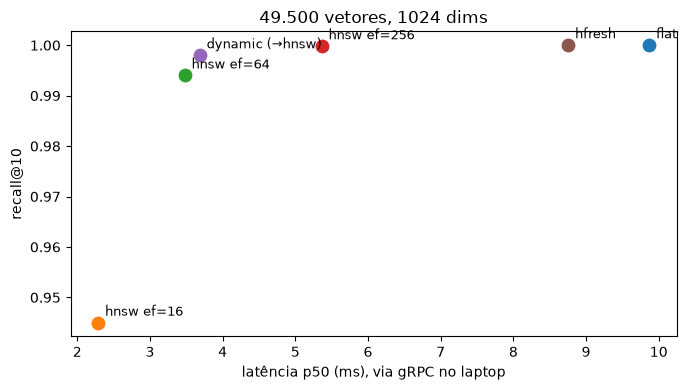

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
for nome, r in resultados.items():
    ax.scatter(r["latência p50 (ms)"], r["recall@10"], s=80)
    ax.annotate(nome, (r["latência p50 (ms)"], r["recall@10"]), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.set_xlabel("latência p50 (ms), via gRPC no laptop"); ax.set_ylabel("recall@10")
ax.set_title("49.500 vetores, 1024 dims")
plt.tight_layout(); plt.show()

Com 50 mil vetores tudo é rápido, até o flat. A diferença aparece com **milhões**: o flat cresce linearmente, o HNSW cresce ~logaritmicamente (mas precisa do grafo em memória), e o HFresh troca um pouco de latência por muito menos RAM.

## Multi-vetor e MUVERA

Modelos como ColBERT e ColPali/ColQwen geram **um vetor por token ou pedaço de imagem**, e comparam com *MaxSim*: cada vetor da pergunta procura seu melhor par no documento. São muito precisos, mas uma página de PDF vira ~750 vetores.

**MUVERA** codifica cada documento multi-vetor num **único vetor de tamanho fixo**; o índice busca nesses vetores e reranqueia os candidatos com MaxSim exato.

In [9]:
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download

tabela_arxiv = pq.read_table(hf_hub_download(utils.ARXIV_REPO, utils.ARXIV_FILE, repo_type="dataset"), columns=["paper_title", "page_number", "colqwen_embedding"])
paginas = [np.array(v, dtype=np.float32) for v in tabela_arxiv.column("colqwen_embedding").to_pylist()]
total = sum(len(p) for p in paginas)
print(f"{len(paginas)} páginas, {total:,} vetores de {paginas[0].shape[1]} dims (~{total / len(paginas):.0f} por página)")

399 páginas, 300,845 vetores de 128 dims (~754 por página)


Perguntas de teste: 32 vetores sorteados de uma página ("um trecho"). A busca deve achar a página de origem. O gabarito é o top 10 por MaxSim exato.

In [10]:
rng = np.random.default_rng(0)
N_TRECHOS = 40
origens = rng.choice(len(paginas), N_TRECHOS, replace=False)
trechos = [paginas[p][rng.choice(len(paginas[p]), 32, replace=False)] for p in origens]

todos = np.vstack(paginas)
pagina_de = np.repeat(np.arange(len(paginas)), [len(p) for p in paginas])


def maxsim_exato(q):
    s = q @ todos.T
    melhor = np.full((len(q), len(paginas)), -np.inf, dtype=np.float32)
    for i in range(len(q)):
        np.maximum.at(melhor[i], pagina_de, s[i])
    return melhor.sum(axis=0)


gabarito_mv = [np.argsort(-maxsim_exato(q))[:K] for q in trechos]


def carregar_multivetor(nome, encoding=None, indice=None):
    client.collections.delete(nome)
    colecao = client.collections.create(
        nome,
        properties=[Property(name="pagina", data_type=DataType.INT)],
        vector_config=Configure.MultiVectors.self_provided(name="colqwen", encoding=encoding, vector_index_config=indice),
    )
    inicio = time.perf_counter()
    with colecao.batch.fixed_size(batch_size=20) as batch:
        for i, v in enumerate(paginas):
            batch.add_object({"pagina": i}, vector={"colqwen": v.tolist()})
    assert not colecao.batch.failed_objects
    utils.wait_for_indexing(client, nome)
    return colecao, time.perf_counter() - inicio


def medir_mv(colecao):
    primeiro = achados = 0
    tempos = []
    for q, origem, certo in zip(trechos, origens, gabarito_mv):
        inicio = time.perf_counter()
        r = colecao.query.near_vector(q.tolist(), target_vector="colqwen", limit=K, return_properties=["pagina"])
        tempos.append((time.perf_counter() - inicio) * 1000)
        ps = [o.properties["pagina"] for o in r.objects]
        primeiro += ps[:1] == [origem]
        achados += len(set(ps) & set(certo.tolist()))
    return {"página certa em 1º": primeiro / N_TRECHOS, "recall@10 (MaxSim)": achados / (N_TRECHOS * K), "latência p50 (ms)": np.median(tempos)}


mv = {}
colecao, t = carregar_multivetor("PaginasMultiVetor", indice=Configure.VectorIndex.hnsw())
mv["HNSW, multi-vetor puro"] = {"vetores no índice": total, "import+índice (s)": t, **medir_mv(colecao)}

Encoding = Configure.VectorIndex.MultiVector.Encoding
colecao, t = carregar_multivetor("PaginasMuvera", encoding=Encoding.muvera(), indice=Configure.VectorIndex.hnsw())
mv["HNSW + MUVERA"] = {"vetores no índice": len(paginas), "import+índice (s)": t, **medir_mv(colecao)}

colecao, t = carregar_multivetor("PaginasHFreshMuvera", encoding=Encoding.muvera(), indice=Configure.VectorIndex.hfresh())
mv["HFresh + MUVERA (v1.40)"] = {"vetores no índice": len(paginas), "import+índice (s)": t, **medir_mv(colecao)}

pd.DataFrame(mv).T.style.format({"vetores no índice": "{:,.0f}", "import+índice (s)": "{:.1f}", "página certa em 1º": "{:.2f}", "recall@10 (MaxSim)": "{:.3f}", "latência p50 (ms)": "{:.1f}"})

,vetores no índice,import+índice (s),página certa em 1º,recall@10 (MaxSim),latência p50 (ms)
"HNSW, multi-vetor puro","300,845",31.0,1.00,1.000,50.1
HNSW + MUVERA,399,7.3,1.00,1.000,54.3
HFresh + MUVERA (v1.40),399,6.2,1.00,0.998,87.3


Com MUVERA o índice guarda **um** vetor por página em vez de ~750: import muito mais rápido e grafo muito menor, com a mesma página encontrada em primeiro lugar.

O HFresh multi-vetor é mais lento aqui porque reranqueia até `rescore_limit=350` candidatos com MaxSim exato, ou seja, quase a coleção inteira (399 páginas). Em coleções grandes, ou com `rescore_limit` menor, a conta muda: o ganho dele é **memória**.

➡️ `05_quantizacao.ipynb`

In [11]:
client.close()